# Generalization analysis — paper figures (C1 audit, C2 UQ, C4 features)
Produces every number and figure for the Water-journal manuscript into `Model/paper_figures/`. Models reuse the hyperparameters tuned in `interp_row_42` (fixed across folds so fold differences reflect data, not tuning).

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings('ignore')
sys.path.insert(0, str(Path.cwd()))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import ldh_pipeline as lp

plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titleweight': 'bold', 'axes.titlesize': 12, 'savefig.dpi': 300,
})
SEED = lp.SEED
FIG_DIR = lp.MODEL_DIR / 'paper_figures'
FIG_DIR.mkdir(exist_ok=True)
print('Figures ->', FIG_DIR)

Figures -> D:\Research_Projects\GreenX_BaoTien_project\Model\paper_figures


In [2]:
df = lp.load_data(lp.DATA_DIR / '20260804_Data_Adsorption.xlsx')
y = df['RR %']
groups = df['Id'].values
X = df.drop(columns=['Id', 'RR %'])
saved = joblib.load(lp.MODEL_DIR / 'interp_row_42' / 'saved_models.joblib')
MODELS = {k: saved[k] for k in ('LR', 'KNN', 'ANN', 'Cubist', 'RF', 'XGB', 'HistGB', 'LGB')}
print(f"{len(df)} rows, {df['Id'].nunique()} studies, {X.shape[1]} features")

1342 rows, 59 studies, 30 features


## C1a. Leave-one-study-out audit
Each of the 59 studies is held out once; models are refit on the remaining 58 with fixed hyperparameters.

In [3]:
loso = lp.loso_evaluation(MODELS, X.reset_index(drop=True), y.reset_index(drop=True), groups)
loso.to_csv(FIG_DIR / 'loso_per_study.csv', index=False)
summary = (loso.groupby('model')[['r2', 'mae', 'rmse']]
           .agg(['mean', 'std']).round(3))
print(summary.columns)
summary.columns = ['_'.join(c) for c in summary.columns]
summary = summary.sort_values('mae_mean').round(2)
summary.to_csv(FIG_DIR / 'loso_summary.csv')
summary

MultiIndex([(  'r2', 'mean'),
            (  'r2',  'std'),
            ( 'mae', 'mean'),
            ( 'mae',  'std'),
            ('rmse', 'mean'),
            ('rmse',  'std')],
           )


,r2_mean,r2_std,mae_mean,mae_std,rmse_mean,rmse_std
model,,,,,,
Cubist,-6.26,25.78,14.73,10.60,16.62,12.51
LGB,-7.29,25.69,15.73,12.33,17.59,14.14
HistGB,-8.77,34.05,15.88,12.47,17.88,14.50
RF,-9.23,36.14,16.34,11.18,18.17,12.68
XGB,-8.00,23.49,17.69,13.17,19.96,15.28
KNN,-14.82,64.96,18.06,16.04,20.25,17.97
LR,-12.37,52.98,26.10,11.19,28.15,12.27
ANN,-14.01,44.71,27.82,20.58,29.92,22.03


In [4]:
summary = summary.sort_values('mae_mean').round(2)
summary.to_csv(FIG_DIR / 'loso_summary.csv')
summary

,r2_mean,r2_std,mae_mean,mae_std,rmse_mean,rmse_std
model,,,,,,
Cubist,-6.26,25.78,14.73,10.60,16.62,12.51
LGB,-7.29,25.69,15.73,12.33,17.59,14.14
HistGB,-8.77,34.05,15.88,12.47,17.88,14.50
RF,-9.23,36.14,16.34,11.18,18.17,12.68
XGB,-8.00,23.49,17.69,13.17,19.96,15.28
KNN,-14.82,64.96,18.06,16.04,20.25,17.97
LR,-12.37,52.98,26.10,11.19,28.15,12.27
ANN,-14.01,44.71,27.82,20.58,29.92,22.03


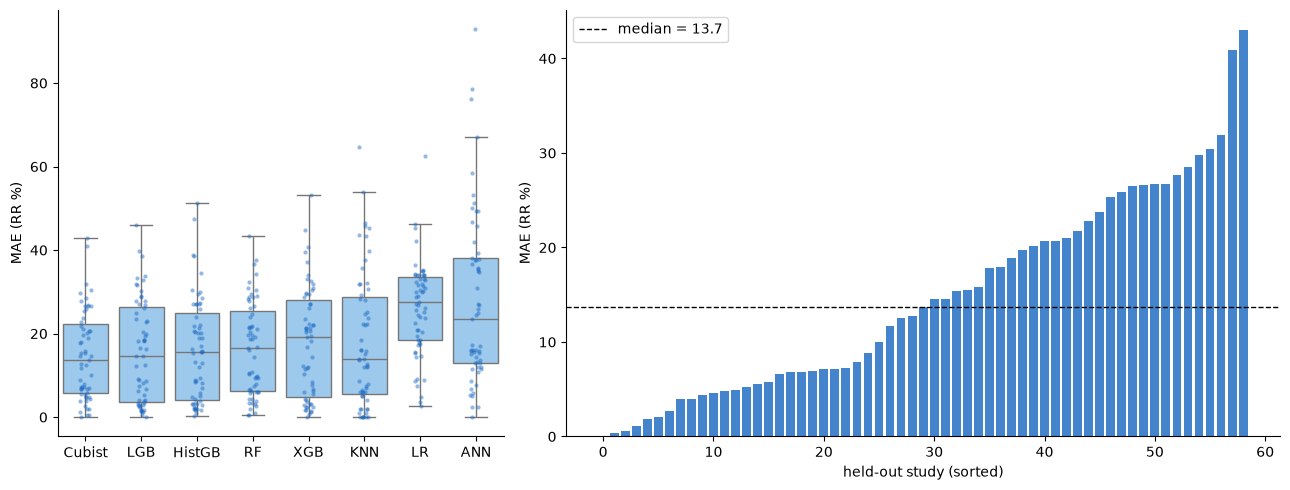

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={'width_ratios': [1, 1.6]})
order = summary.index.tolist()
sns.boxplot(data=loso, x='model', y='mae', order=order, ax=axes[0], color='#90CAF9',
            showfliers=False)
sns.stripplot(data=loso, x='model', y='mae', order=order, ax=axes[0], color='#1565C0',
              alpha=0.45, size=3)
axes[0].set_xlabel(''); axes[0].set_ylabel('MAE (RR %)')

best = order[0]
per_study = (loso[loso.model == best].sort_values('mae')
             .reset_index(drop=True))
axes[1].bar(range(len(per_study)), per_study['mae'], color='#1565C0', alpha=0.8)
axes[1].set_xlabel('held-out study (sorted)'); axes[1].set_ylabel('MAE (RR %)')
axes[1].axhline(per_study['mae'].median(), ls='--', color='k', lw=1,
                label=f"median = {per_study['mae'].median():.1f}")
axes[1].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig_loso_audit.png', bbox_inches='tight')
plt.show()

## C1b. Interpolation vs unseen-study performance, and learning curve

In [6]:
interp = pd.read_csv(lp.MODEL_DIR / 'interp_row_42' / 'model_scores.csv', index_col=0)
loso_med = loso.groupby('model')['mae'].median()
cmp = pd.DataFrame({'interpolation MAE (hold-out)': interp['test_mae'],
                    'unseen-study MAE (LOSO median)': loso_med}).dropna()
cmp = cmp.sort_values('interpolation MAE (hold-out)').round(2)
cmp.to_csv(FIG_DIR / 'interp_vs_loso.csv')
cmp

,interpolation MAE (hold-out),unseen-study MAE (LOSO median)
HistGB,5.17,15.53
LGB,5.29,14.71
XGB,5.61,19.14
KNN,7.39,14.00
RF,8.29,16.51
Cubist,8.35,13.68
ANN,14.19,23.38
LR,18.20,27.45


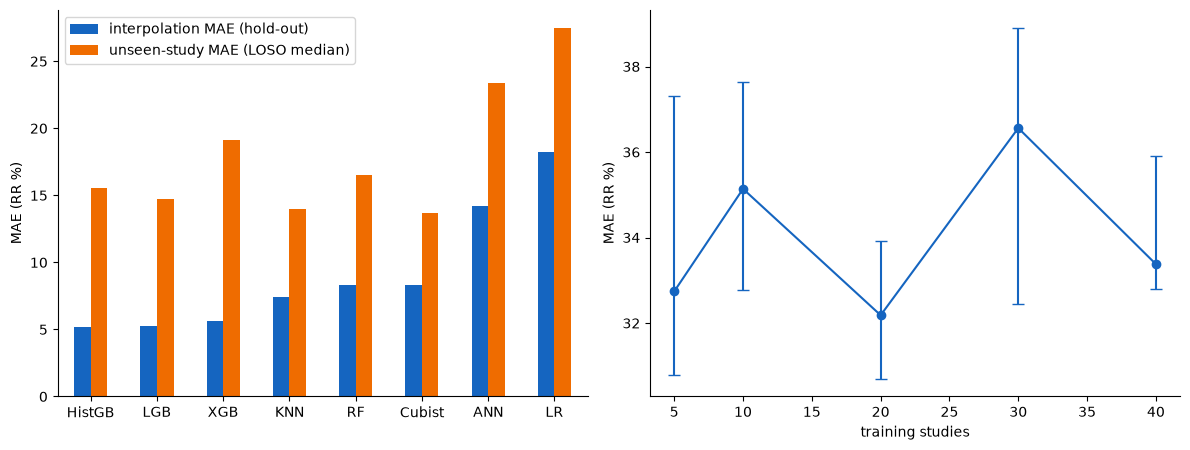

In [7]:
lc = lp.learning_curve_by_studies(MODELS['HistGB'], X, y, groups,
                                  sizes=(5, 10, 20, 30, 40), n_repeats=10)
lc.to_csv(FIG_DIR / 'learning_curve.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
cmp.plot.bar(ax=axes[0], rot=0, color=['#1565C0', '#EF6C00'])
axes[0].set_ylabel('MAE (RR %)')

g = lc.groupby('n_studies')['mae']
axes[1].errorbar(g.median().index, g.median(), yerr=[g.median()-g.quantile(0.25),
                 g.quantile(0.75)-g.median()], marker='o', color='#1565C0', capsize=4)
axes[1].set_xlabel('training studies'); axes[1].set_ylabel('MAE (RR %)')
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig_learning_curve.png', bbox_inches='tight')
plt.show()

## C2. Conformal prediction intervals and applicability domain
Split-conformal 90% intervals under both tasks. For the new-study task the calibration set is grouped by study, matching deployment.

In [8]:
model = MODELS['HistGB']
rows = []

# (a) interpolation task: same protocol as interp_row_42
keep = ~X.duplicated(keep='first')
Xd, yd, gd = X[keep], y[keep], groups[keep]
Xtr, Xte, ytr, yte, _ = lp.make_split(Xd, yd, groups=None, test_size=0.2, seed=SEED)
cf_i = lp.split_conformal(model, Xtr, ytr, Xte, yte, alpha=0.1)
rows.append({'task': 'interpolation', 'nominal': 0.90, 'coverage': cf_i['coverage'],
             'half_width_q': cf_i['q']})

# (b) new-study task: grouped split + grouped calibration
Xtr_g, Xte_g, ytr_g, yte_g, gtr = lp.make_split(Xd, yd, groups=gd, test_size=0.2, seed=SEED)
cf_g = lp.split_conformal(model, Xtr_g, ytr_g, Xte_g, yte_g, alpha=0.1, groups_tr=gtr)
rows.append({'task': 'unseen studies', 'nominal': 0.90, 'coverage': cf_g['coverage'],
             'half_width_q': cf_g['q']})

conf_table = pd.DataFrame(rows).round(3)
conf_table.to_csv(FIG_DIR / 'conformal_coverage.csv', index=False)
conf_table

,task,nominal,coverage,half_width_q
0,interpolation,0.9,0.937,19.353
1,unseen studies,0.9,0.992,67.698


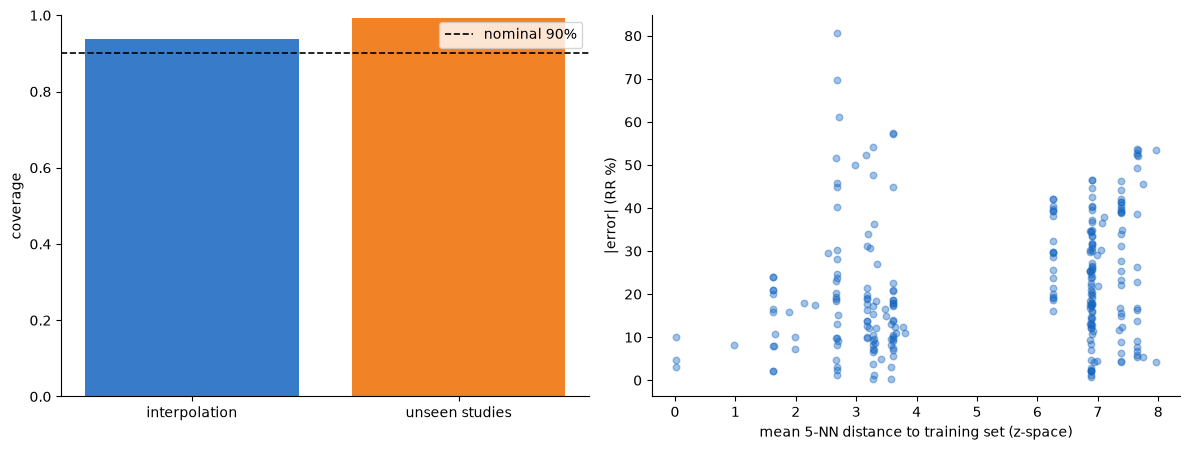

corr(AD distance, |error|) = 0.217


In [9]:
ad = lp.applicability_domain(cf_g['model'], Xtr_g, Xte_g)
abs_err = np.abs(np.asarray(yte_g, dtype=float) - cf_g['pred'])
r = np.corrcoef(ad, abs_err)[0, 1]
pd.DataFrame({'ad_distance': ad, 'abs_error': abs_err}).to_csv(
    FIG_DIR / 'applicability_domain.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
axes[0].bar(conf_table['task'], conf_table['coverage'], color=['#1565C0', '#EF6C00'],
            alpha=0.85)
axes[0].axhline(0.9, ls='--', color='k', lw=1.2, label='nominal 90%')
axes[0].set_ylim(0, 1)
axes[0].set_ylabel('coverage'); axes[0].legend()

axes[1].scatter(ad, abs_err, alpha=0.4, s=22, color='#1565C0')
axes[1].set_xlabel('mean 5-NN distance to training set (z-space)')
axes[1].set_ylabel('|error| (RR %)')
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig_conformal_ad.png', bbox_inches='tight')
plt.show()
print(f'corr(AD distance, |error|) = {r:.3f}')

## C4. Chemistry-informed features
Adds `pH − pHpzc` (electrostatic driving force), `Ci/AD` (initial loading), and the hydrophobicity interaction; compares both tasks with/without, then reads SHAP dependence mechanistically.

In [10]:
cfg_eng = lp.ExperimentConfig(name='interp_row_eng_42', split_mode='row',
                              dedup_features=True, engineered_features=True,
                              models=("Cubist", "RF", "XGB", "HistGB", "LGB"))
run_eng = lp.run_experiment(cfg_eng, df)

X_eng = lp.add_engineered_features(X)
loso_eng = lp.loso_evaluation({'HistGB': run_eng['results']['HistGB']['model']},
                              X_eng.reset_index(drop=True), y.reset_index(drop=True),
                              groups)
feat_cmp = pd.DataFrame({
    'interpolation test MAE': {
        'raw features': interp.loc['HistGB', 'test_mae'],
        'with engineered': run_eng['table'].loc['HistGB', 'test_mae']},
    'unseen-study median MAE': {
        'raw features': loso_med['HistGB'],
        'with engineered': loso_eng['mae'].median()},
}).round(2)
feat_cmp.to_csv(FIG_DIR / 'engineered_features_effect.csv')
feat_cmp

[interp_row_eng_42] dropped 83 exact feature-duplicate rows
[interp_row_eng_42] split=row  train=1007  test=252  features=33
[BorutaShap] Starting feature selection...


  0%|          | 0/20 [00:00<?, ?it/s]

[BorutaShap] Suggested dropping 11 features.
[BorutaShap] OVERRIDE: Saved 3 Abraham variable(s) from being dropped.
[BorutaShap] Final number of features dropping: 8
[interp_row_eng_42] Features remaining after BorutaShap: 25
--- Optuna tuning RF (30 trials) ---
[*] RF best params: {'n_estimators': 139, 'max_depth': 15, 'min_samples_leaf': 3}
--- Optuna tuning XGB (30 trials) ---
[*] XGB best params: {'n_estimators': 423, 'learning_rate': 0.09522440046089231, 'max_depth': 14, 'min_child_weight': 8}
--- Optuna tuning HistGB (30 trials) ---
[*] HistGB best params: {'max_iter': 383, 'learning_rate': 0.12814073342908538, 'max_depth': 13, 'min_samples_leaf': 4}
--- Optuna tuning LGB (30 trials) ---
[*] LGB best params: {'n_estimators': 440, 'learning_rate': 0.1532739771558765, 'max_depth': 9, 'min_child_samples': 5}
--- Cubist ---
[*] best params: {'n_committees': 8, 'neighbors': 1}
    Train      R2  0.9433 | MAE   3.6574
    CV (valid) R2  0.7866 | MAE   8.2847
    Test       R2  0.8037 |

,interpolation test MAE,unseen-study median MAE
raw features,5.17,15.53
with engineered,5.63,16.17


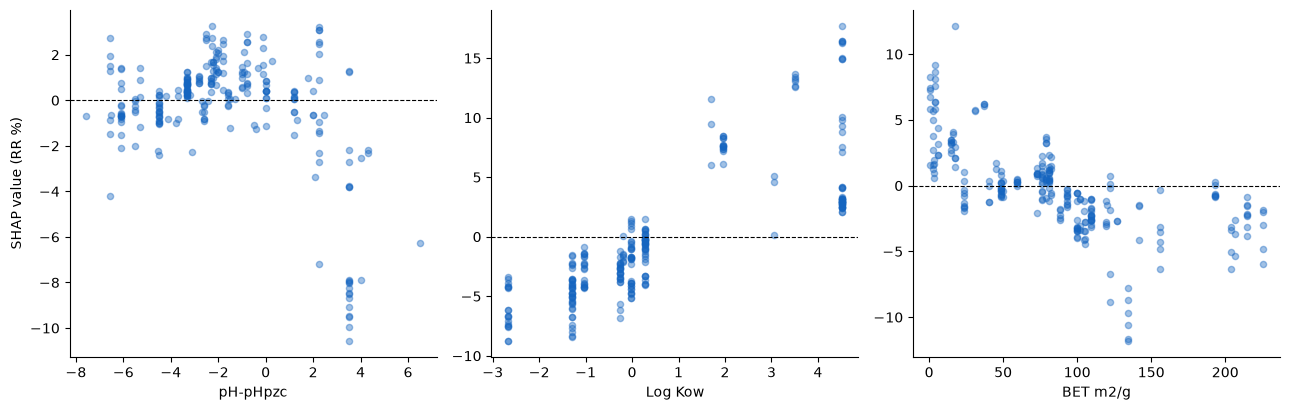

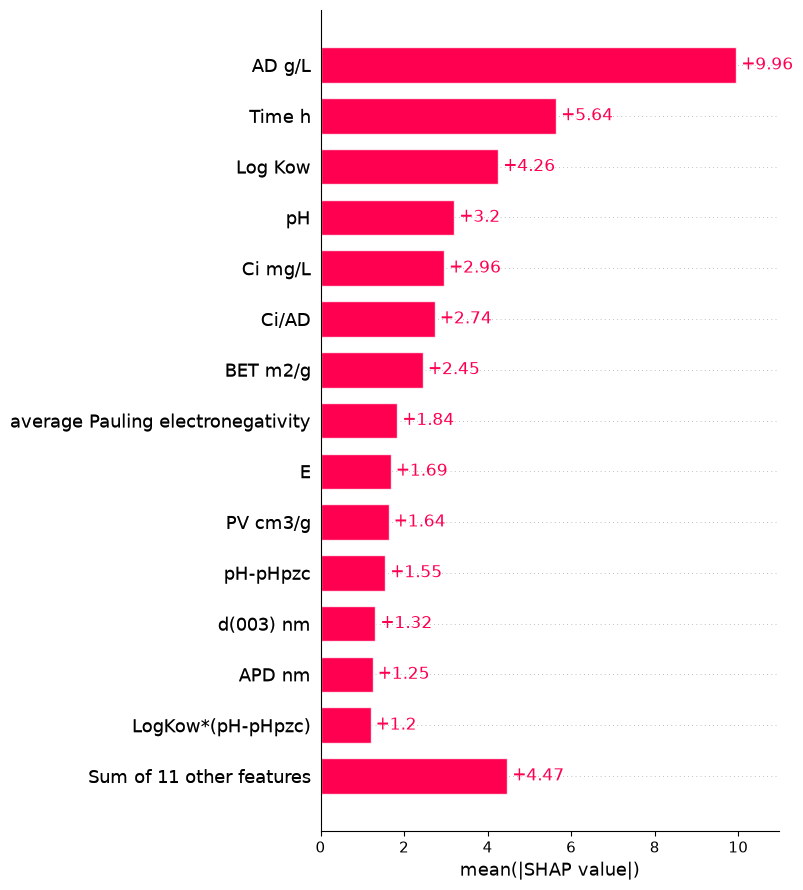

In [11]:
import shap
res_best = run_eng['results']['LGB']
sv, names = lp.shap_summary(res_best, run_eng['X_test'])
sv.feature_names = names

fig = plt.figure(figsize=(13, 4.2))
for i, feat in enumerate(['pH-pHpzc', 'Log Kow', 'BET m2/g']):
    ax = plt.subplot(1, 3, i + 1)
    j = names.index(feat)
    ax.scatter(sv.data[:, j], sv.values[:, j], alpha=0.4, s=20, color='#1565C0')
    ax.axhline(0, color='k', lw=0.8, ls='--')
    ax.set_xlabel(feat); ax.set_ylabel('SHAP value (RR %)' if i == 0 else '')
    
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig_shap_mechanism.png', bbox_inches='tight')
plt.show()

shap.plots.bar(sv, max_display=15, show=False)
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig_shap_bar_eng.png', bbox_inches='tight')
plt.show()

## Outputs
All CSVs and figures for the manuscript are in `Model/paper_figures/`; every number cited in the paper traces back to one of these files.